## <font color='black'> FlyFinder version 1.0 (4-panel images - <u>Andrew's Camera</u> )</font>
This notebook provides the sequence of instructions and commands for training a random forest classifer <br>
used during segmentation. It also give instructions and the commands of the whole process of segmentation.
<br><br>
If the model has been trained for a specific study setup, there will be no need to retrain, the user can <br>
immediately proceed to section 2 for first segmentation.

<u> Used camera model:</u><br>
...<br>
<u>Settings</u>:<br>
...


### Section 1: Training the classifier

- [1.1. Setting up initial parameters](#l1)
   
- [1.2. Training the random forest classifier](#l2)

### Section 2: Segmentation of images]
   
- [2.1. Performing the first segmentation](#l3)

- [2.2. Manual editing the failed images ](#l4)

- [2.3. Performing the second segmentation](#l5)

- [2.4. Creating the table of fly coordinates ](#l6)

- [2.5. Calculating the nearest neighbors distances](#l7)
 

### <font color='blue'><b>Section 1: Training the classifier</b></font>

### <font color='blue'> 1.0. Importing FlyFinder Functions </font>

In [8]:
from FF_utils import *

<a name="l1"></a>
### <font color='blue'> 1.1. Setting up initial parameters </font>

<b>  - The parameters for drawing:</b>

In [2]:
# Defining the colors
blue=(0,0,255); red=(255,0,0); magenta=(255,0,255); 

# Setting the line, point and figure size
pen=5;  # if pen=5 or less and the bottom lines is not visible, set it to 10
point=15; 
figSize=5

<b>  - Cropping the sides, masking the background and visualization (4-panel images): </b><br>
The <b>cropLeft</b>, <b>cropRight</b>, <b>cropTop</b> and <b>cropBottom</b> are used to crop the left, right,<br> 
top and  bottom sides the input images in case it is necessary.<br>
The <b>bottomMargin</b> and <b>topGap</b> parameters are used to demarcate the triangle such that the area inside the <br>
lines will be used while the area outside will be ignored. Different values can be tired to determine the best<br>
fit for a particular imaging setup. The demarcated pictures can be viewed in the next command

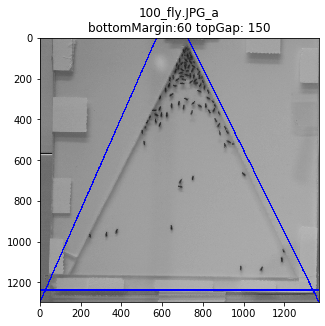

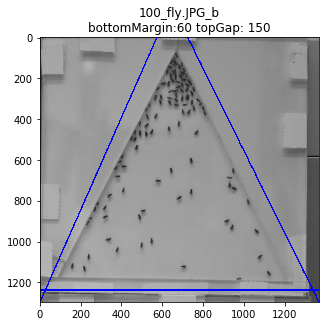

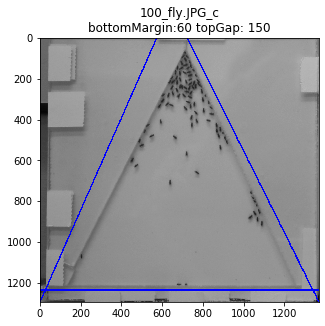

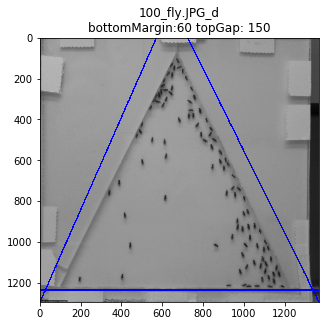

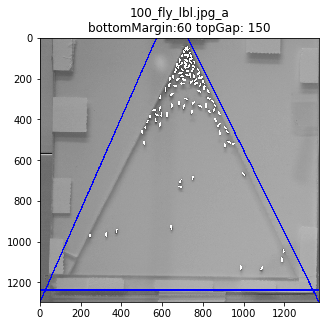

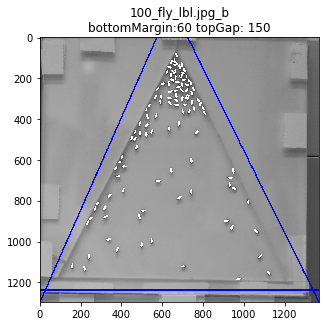

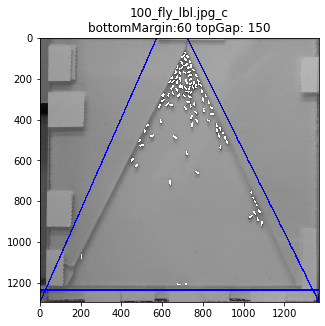

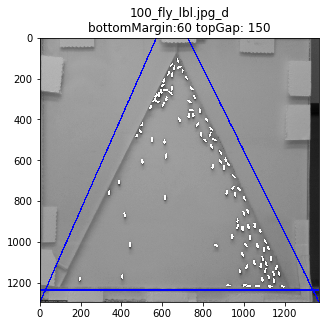

In [3]:
#Cropping the input image if necessary (pxl)
cropLeft4=550
cropRight4=600
cropTop4=0
cropBottom4=0

# Applying the mask:
# bottomMargin : correspond to the marging applied to the bottom of the image
# topgap : correspond to the distance between the two sides-triangle lines (at the top of the picture)   

bottomMargin4=60
topGap4=150

## Visualization
imagPath_="/varidata/research/projects/mnp/tool.dev/FlyFinder_v1.0/train_4p_Andrew/"
viewImageMargins4Panel(imagPath=imagPath_, bottomMargin=bottomMargin4, topGap=topGap4, cropLeft=cropLeft4, cropRight=cropRight4, cropTop=cropTop4, cropBottom=cropBottom4,  marginCol=blue, figSize=figSize, pen_=pen) 

<a name="l2"></a>
### <font color='blue'> 1.2. Training the random forest classifier </font>

After getting the best values of <b>bottomMargin</b> and <b>topGap</b> that best demarcate the <br>
triangle (i.e bottomMargin=60 topGap=10), they will be used to traini either a 1 or 4Panel-based random forest classifier.<br>

We can first see the script parameters like this:

In [4]:
! python FlyFinder_train.py --help


-* FlyFinder_v1.0 *-

usage: FlyFinder_train.py [-h] --modelName MODELNAME --plateType PLATETYPE
                          --nGaussianFilters NGAUSSIANFILTERS --nMedianFilters
                          NMEDIANFILTERS --nEstimators NESTIMATORS
                          --bottomMargin BOTTOMMARGIN --topGap TOPGAP
                          --cropLeft CROPLEFT --cropRight CROPRIGHT --cropTop
                          CROPTOP --cropBottom CROPBOTTOM --inPath INPATH

optional arguments:
  -h, --help            show this help message and exit
  --modelName MODELNAME
                        the name you want to give to your random forest
                        classifier.
  --plateType PLATETYPE
                        the 1 panel plate '1panel' or 4 panel plate '4panel'.
  --nGaussianFilters NGAUSSIANFILTERS
                        the number of gaussian filters. Default=40.
  --nMedianFilters NMEDIANFILTERS
                        the number of median filters. Default=40.
  --nEstimators N

<b>- Check if there are trained models:</b>

In [5]:
! python FlyFinder_train.py models


-* FlyFinder_v1.0 *-

Available trained random forest classifiers:

M1Panel_GF40_MF10_Es30_mar100_topG50_RFC
M4Panel_GF40_MF10_Es30_mar100_topG50_RFC




<b>- Viewing the directory of images used for segmentation: </b><br>
Note: the labelled image for training must have '_lbl' added to its name right before the '.jpg' file extension.

In [6]:
!ls /varidata/research/projects/mnp/tool.dev/FlyFinder_v1.0/train_4p_Andrew/

100_fly.JPG  100_fly_lbl.jpg


<b>Executing the script that trains the random forest classifer (4-panel images):</b>

<u>Training settings:</u><br>
plateType = 4Panel (this can be changed to 1Panel if dealing with 1-panel/triangle images)<br>
Number of gaussian filters (nGaussianFilters=40) <br>
Median filters (nMedianFilters=10) <br>
Number of trees (nEstimators=30) <br>
bottomMargin = 60 <br> 
topGap = 150 <br>
cropLeft=550 <br>
cropRight=600 <br>
cropTop=0<br>
cropBottom=0<br>

In [10]:

! python FlyFinder_train.py --modelName "M4Panel_GF40_MF10_Es30_mar60_topG150_RFC_Andrew" \
                            --plateType 4Panel \
                            --nGaussianFilters=40 \
                            --nMedianFilters=10 \
                            --nEstimators 30 \
                            --bottomMargin 60 \
                            --topGap 150 \
                            --cropLeft 550 \
                            --cropRight 600 \
                            --cropTop 0 \
                            --cropBottom 0 \
                            --inPath /varidata/research/projects/mnp/tool.dev/FlyFinder_v1.0/train_4p_Andrew/


-* FlyFinder_v1.0 *-


Training a random forest classifier for image segmentation ( 4Panel images) 
----------------------------------------------------------------------------------

Original images:['100_fly.jpg']
Labeled images: ['100_fly_lbl.jpg']
Training set size: 1 files

100_fly.jpg	100_fly_lbl.jpg

  -- Processing panel a --
  (903281, 51)

  -- Processing panel b --
  (1805971, 51)

  -- Processing panel c --
  (2708489, 51)

  -- Processing panel d --
  (3610416, 51)
 
Dimensions after removing dupliate rows:
 (2307103, 51)
Trainning the RandomForestClassifier, number of estimators =  30 


 Confusion matrix:
[[222874    569]
 [  1017   6251]]

Accuracy = 0.9931255986927368

Feature_importance:
--------------------
<class 'pandas.core.series.Series'>
Median_1          0.151111
Median_3          0.136980
 Gaussian_1       0.082455
Median_5          0.080464
Original_image    0.058011
 Gaussian_2       0.053154
Median_2          0.052473
Median_4          0.050014
Median_6   

<b>- The resulting model has:</b><br>
Accuracy = 0.993
Training duration =  5.0 min 

<b>- Viewing the fly Area density plot</b>

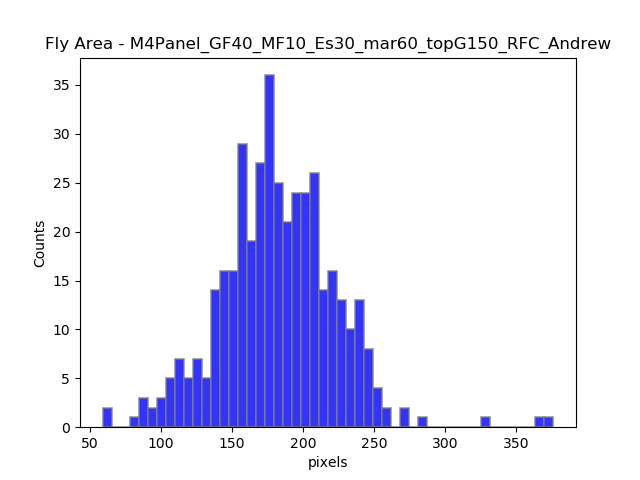

In [11]:

## Viewing the flyArea density plot
from IPython.display import Image
Image(filename="/varidata/research/projects/mnp/tool.dev/FlyFinder_v1.0/RFC_model/M4Panel_GF40_MF10_Es30_mar60_topG150_RFC_Andrew_flyArea.png", width=400, height=400)

### <font color='blue'><b>Section 2: Segmentation of images</b></font>

### <font color='blue'> 2.0. Importing FlyFinder functions </font>

In [1]:
from FF_utils import *

<a name="l3"></a>
### <font color='blue'> 2.1. Performing the first segmentation </font>


 Viewing the script parameters of the script that perfroms the first segmentation:

In [2]:
! python FlyFinder_first_segmentation.py --help


-* FlyFinder_v1.0 *-

usage: FlyFinder_first_segmentation.py [-h] --modelName MODELNAME --plateType
                                       PLATETYPE --nGaussianFilters
                                       NGAUSSIANFILTERS --nMedianFilters
                                       NMEDIANFILTERS --bottomMargin
                                       BOTTOMMARGIN --topGap TOPGAP --cropLeft
                                       CROPLEFT --cropRight CROPRIGHT
                                       --cropTop CROPTOP --cropBottom
                                       CROPBOTTOM --maxArea MAXAREA --minArea
                                       MINAREA --numFlies NUMFLIES --inPath
                                       INPATH

optional arguments:
  -h, --help            show this help message and exit
  --modelName MODELNAME
                        the name of the random forest classifier to use.
  --plateType PLATETYPE
                        the 1 panel plate '1panel' or 4 panel plate '4pa

<b> - Setting up initial parameters (4-panel images) </b><br>
Here we use the same image parameter as previous

In [3]:
## Initial parameters for drawing

blue=(0,0,255); red=(255,0,0); magenta=(255,0,255); 
pen=5 
point=15
figSize=5

<b>- Visualization</b><br>
This verifies that the bottomMargin and topGap work for all images. Adjust if needed.

/varidata/research/projects/mnp/tool.dev/FlyFinder_v1.0/FF_utils.py:205: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`).
  out=plt.figure(figsize = (size,size))


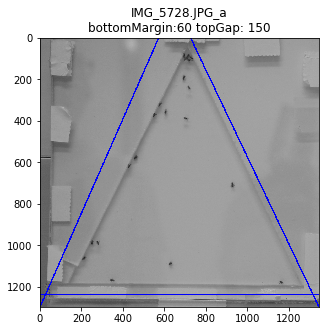

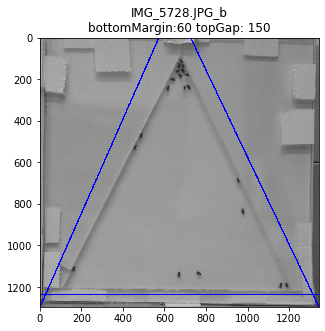

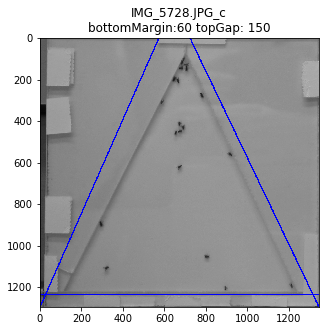

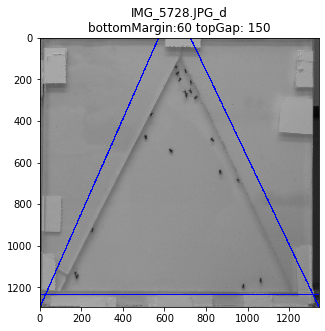

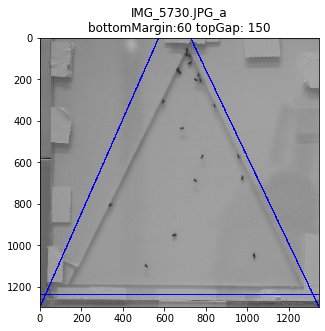

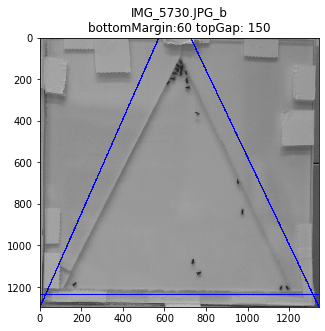

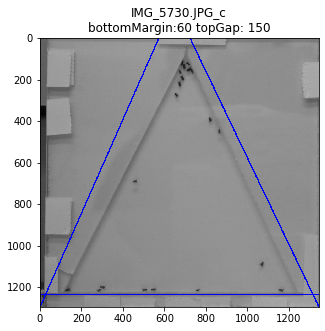

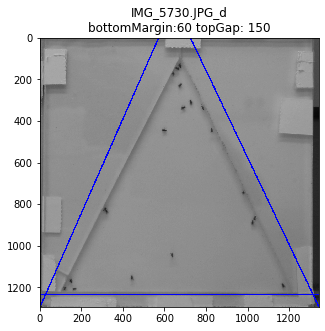

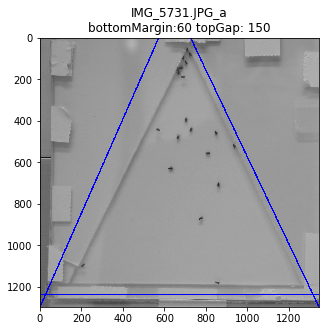

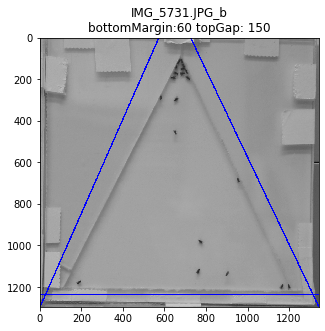

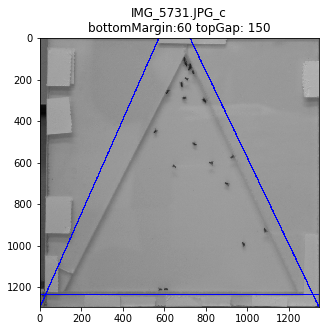

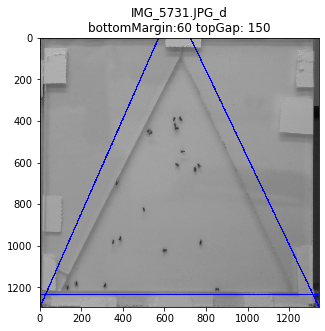

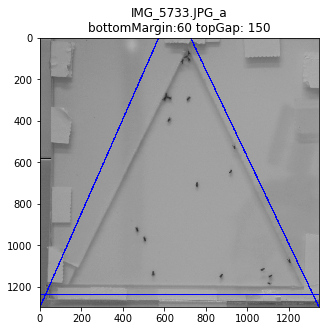

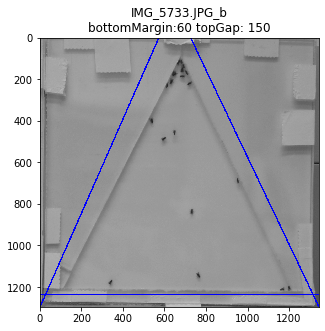

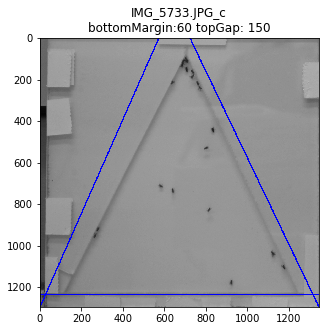

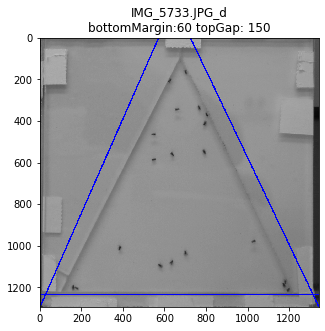

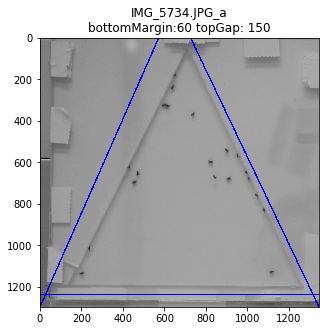

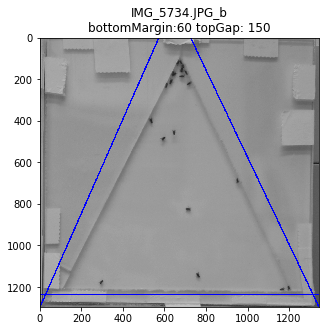

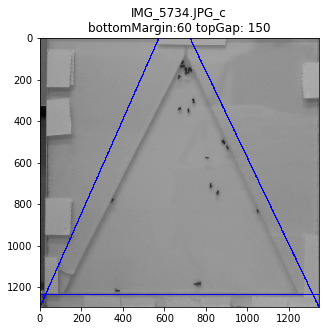

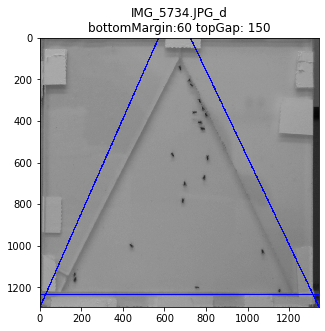

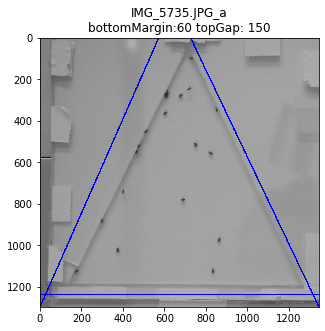

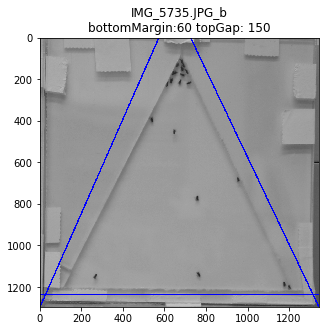

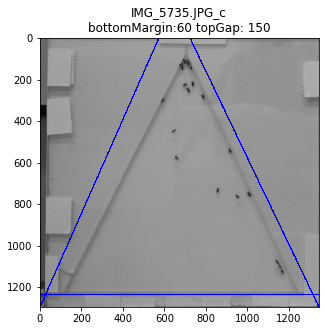

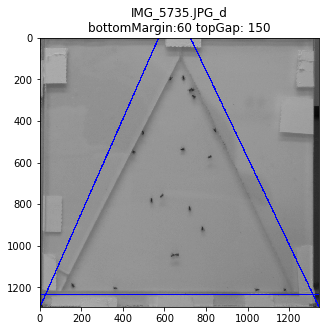

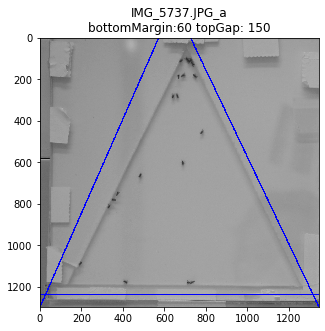

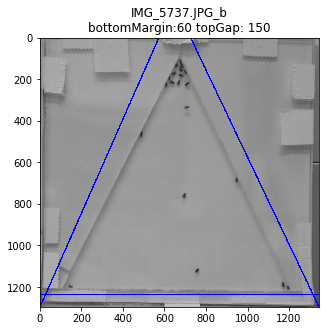

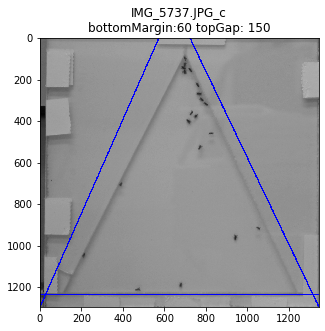

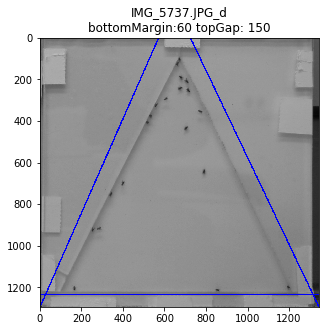

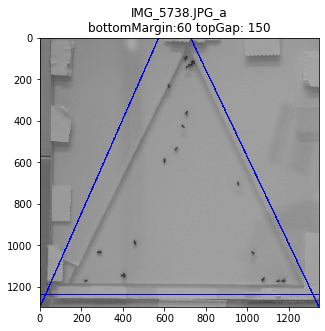

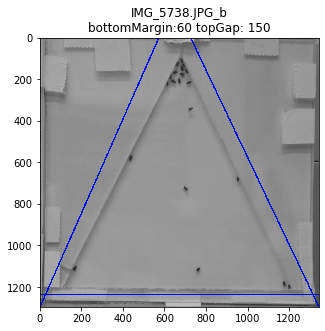

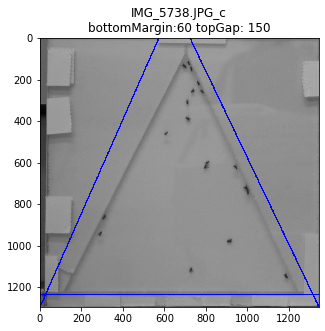

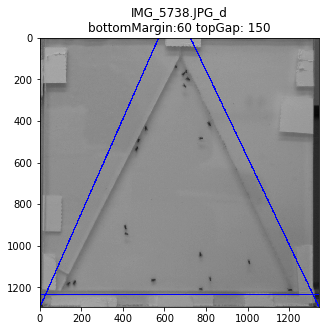

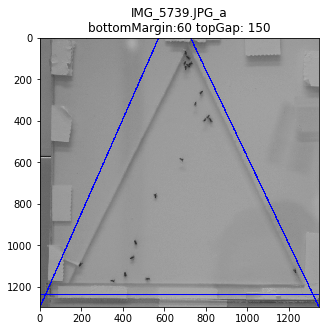

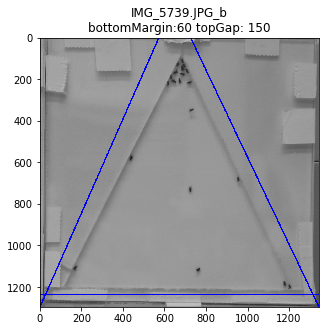

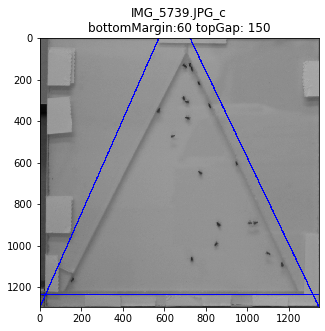

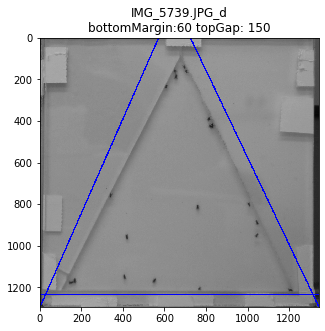

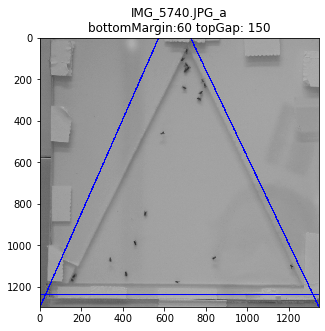

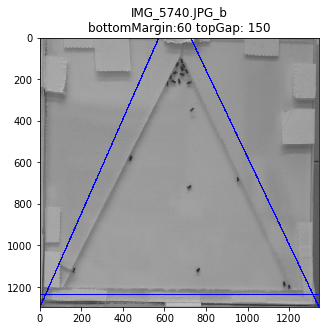

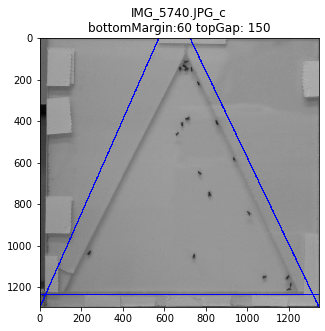

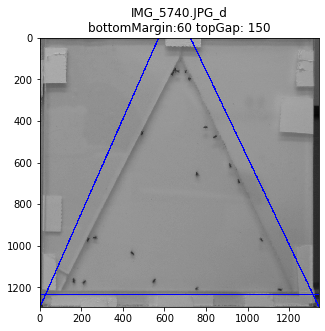

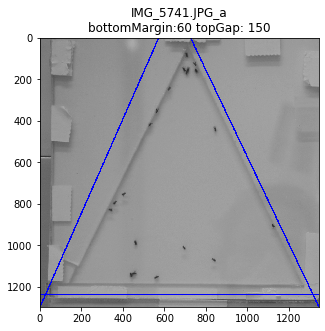

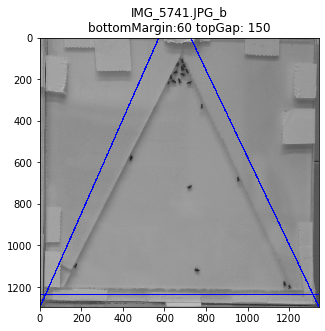

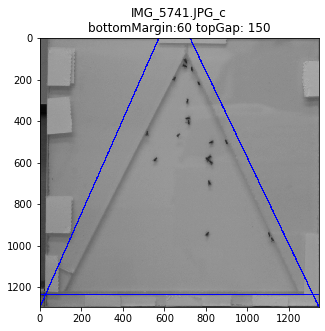

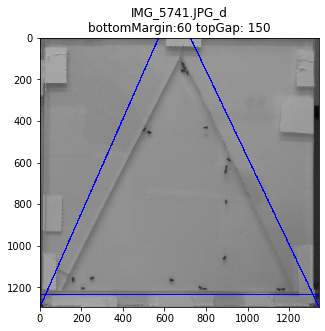

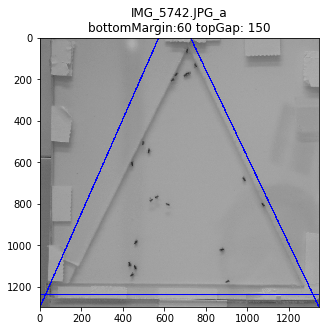

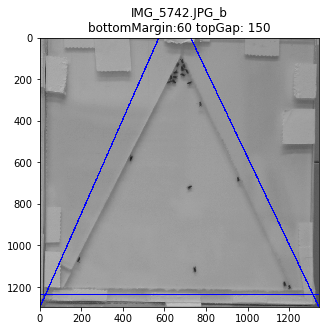

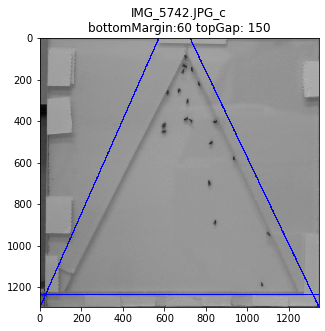

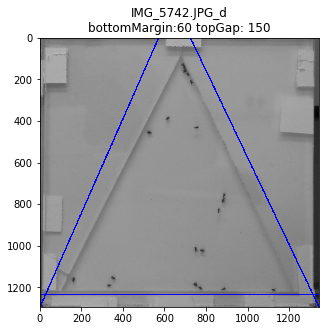

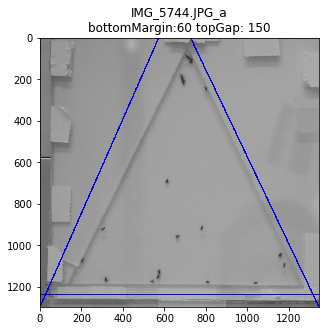

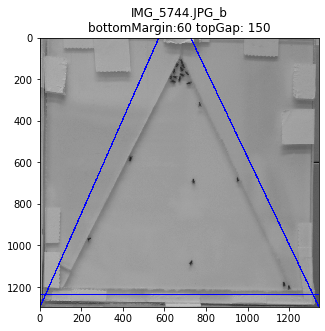

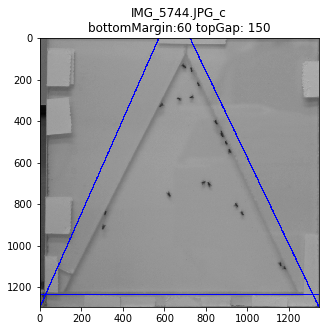

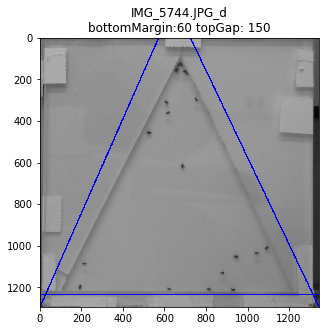

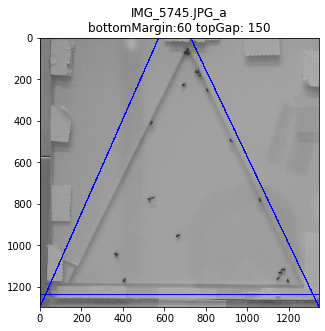

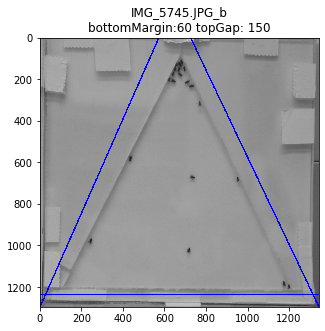

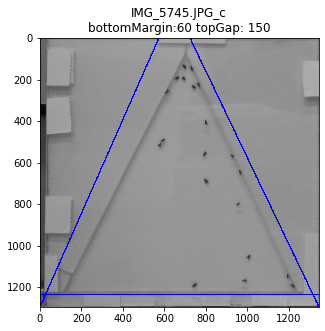

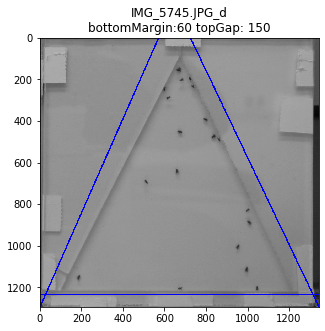

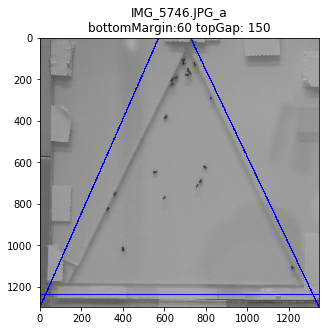

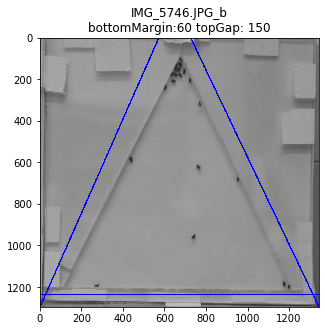

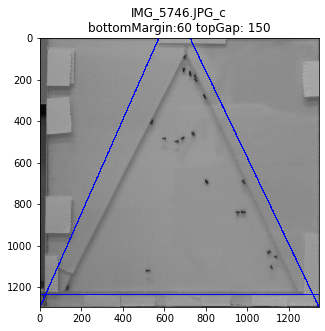

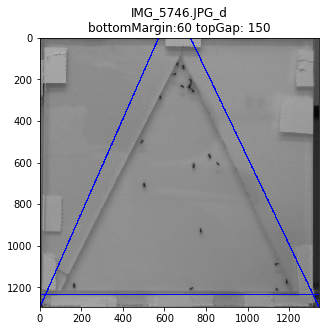

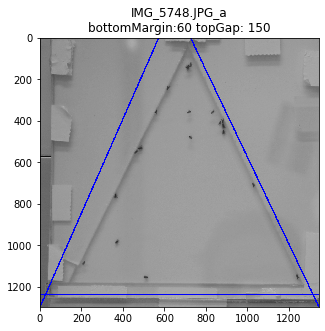

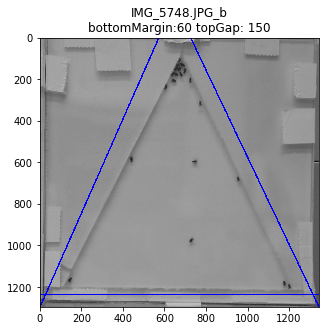

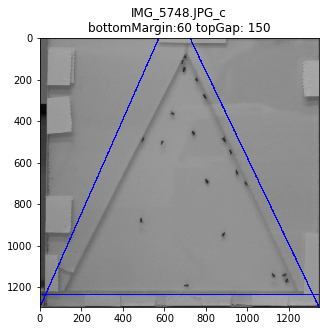

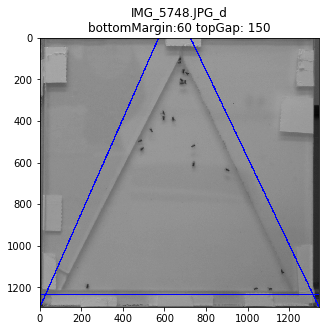

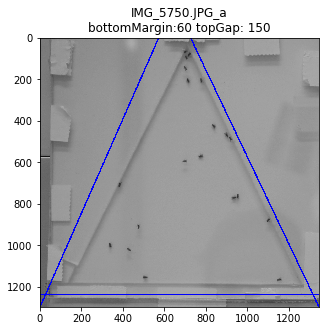

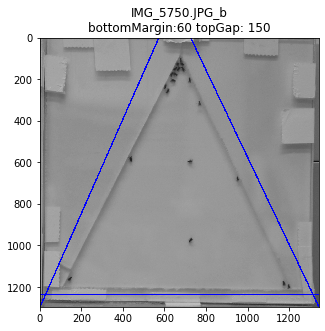

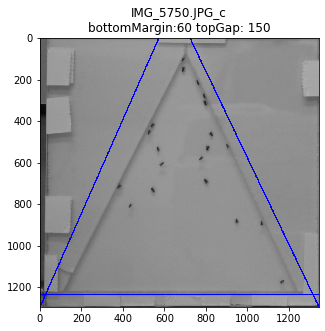

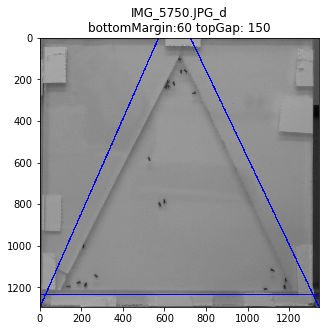

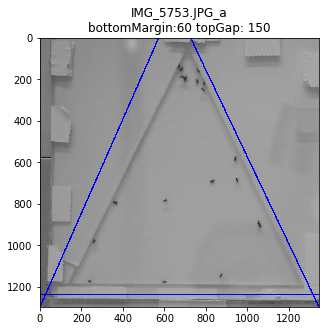

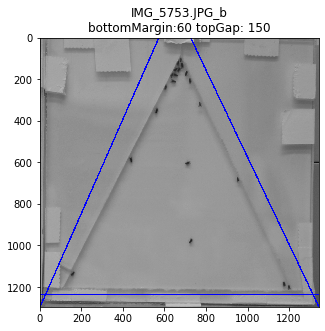

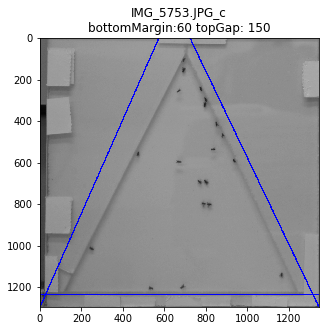

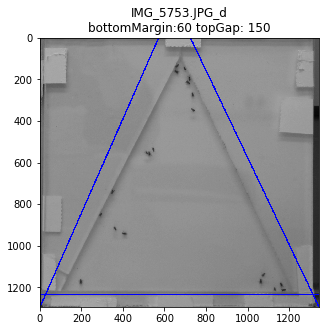

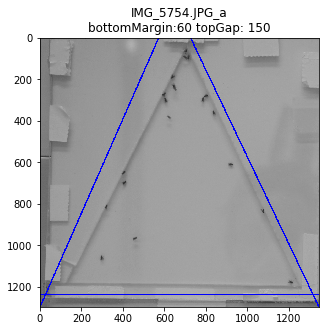

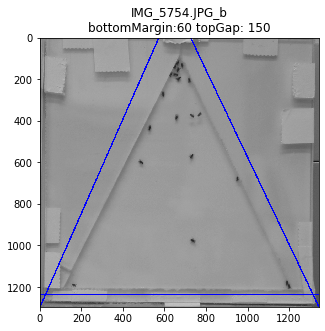

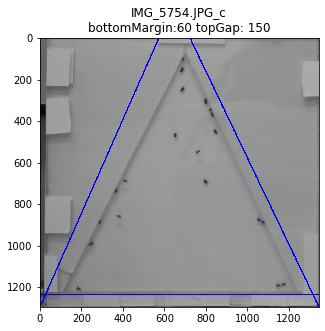

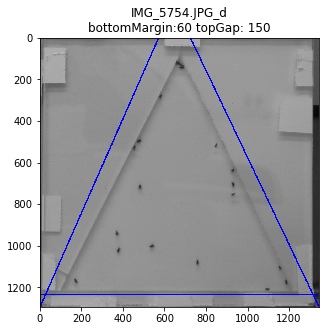

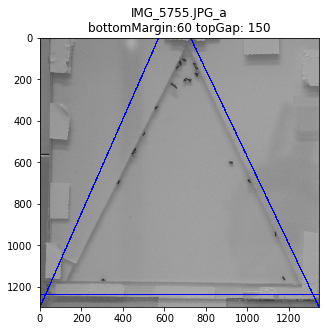

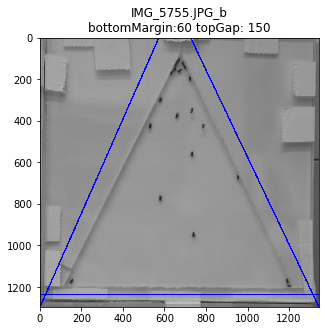

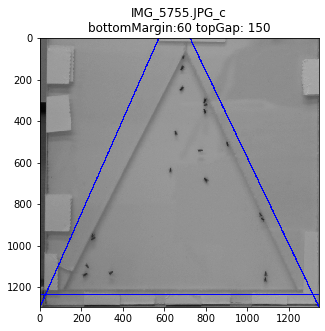

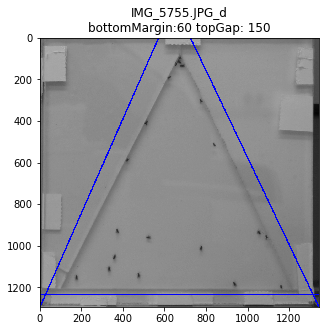

In [4]:
#Cropping the input image if necessary (pxl)
cropLeft4=550
cropRight4=650
cropTop4=0
cropBottom4=0

# Applying the mask:
# bottomMargin : correspond to the marging applied to the bottom of the image
# topgap : correspond to the distance between the two sides-triangle lines (at the top of the picture)   

bottomMargin4=60
topGap4=150

## Visualization
imagPath_="/varidata/research/projects/mnp/tool.dev/FlyFinder_v1.0/test_4p_Andrew/"
viewImageMargins4Panel(imagPath=imagPath_, bottomMargin=bottomMargin4, topGap=topGap4, cropLeft=cropLeft4, cropRight=cropRight4, cropTop=cropTop4, cropBottom=cropBottom4,  marginCol=blue, figSize=figSize, pen_=pen) 


<b>- Checking the names of trained models: both train and first segmentation scripts can help checking available models:</b><br>
Both <i>FlyFinder_train.py</i> and <i> FlyFinder_first_segmentation.py</i> functions can show trained/available models if passe the 'models' parameter.

In [8]:
! python FlyFinder_train.py models


-* FlyFinder_v1.0 *-

Available trained random forest classifiers:

M1Panel_GF40_MF10_Es30_mar100_topG50_RFC
M4Panel_GF40_MF10_Es30_mar60_topG150_RFC_Andrew
M4Panel_GF40_MF10_Es30_mar100_topG50_RFC




In [7]:
! python FlyFinder_first_segmentation.py models


-* FlyFinder_v1.0 *-

Avalable random forest classifiers:

M1Panel_GF40_MF10_Es30_mar100_topG50_RFC
M4Panel_GF40_MF10_Es30_mar60_topG150_RFC_Andrew
M4Panel_GF40_MF10_Es30_mar100_topG50_RFC




<b>- Checking the content of the input directory:</b><br>
The directory must contain the images in jpeg format. The file name should end with '.jpg' or '.JPG'

In [9]:
!ls /varidata/research/projects/mnp/tool.dev/FlyFinder_v1.0/test_4p_Andrew/

FinalFigures.dist.pdf  IMG_5732.JPG  IMG_5739.JPG  IMG_5746.JPG  IMG_5753.JPG
FinalTable.csv	       IMG_5733.JPG  IMG_5740.JPG  IMG_5747.JPG  IMG_5754.JPG
FinalTable.dist.csv    IMG_5734.JPG  IMG_5741.JPG  IMG_5748.JPG  IMG_5755.JPG
IMG_5728.JPG	       IMG_5735.JPG  IMG_5742.JPG  IMG_5749.JPG  log
IMG_5729.JPG	       IMG_5736.JPG  IMG_5743.JPG  IMG_5750.JPG  out
IMG_5730.JPG	       IMG_5737.JPG  IMG_5744.JPG  IMG_5751.JPG  outf
IMG_5731.JPG	       IMG_5738.JPG  IMG_5745.JPG  IMG_5752.JPG


<b>- Running the first segmentation script:</b></br>
The script can be run in <u>parallel</u> using the <b>mpiexec</b> command and by specifying the number <br>
of cores (processors) using the <b>-n</b> parameter. The script can also be run in serial using simply the following command:<br>
<i>python FlyFinder_first_segmentation.py {add command line arguments} </i>
<br><br>
Example of runing the script in parallel:

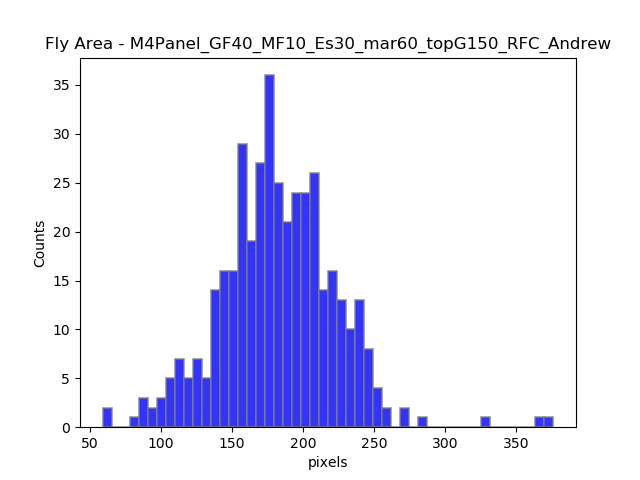

In [10]:
from FF_utils import *


## Viewing the flyArea density plot
from IPython.display import Image
Image(filename="/varidata/research/projects/mnp/tool.dev/FlyFinder_v1.0/RFC_model/M4Panel_GF40_MF10_Es30_mar60_topG150_RFC_Andrew_flyArea.png", width=400, height=400)

In [22]:
! mpiexec -n 12  python FlyFinder_first_segmentation.py --modelName M4Panel_GF40_MF10_Es30_mar60_topG150_RFC_Andrew \
                                                        --plateType 4Panel \
                                                        --minArea 70 \
                                                        --maxArea 240 \
                                                        --nGaussianFilters 40 \
                                                        --nMedianFilters 10 \
                                                        --bottomMargin 60 \
                                                        --topGap 150 \
                                                        --cropLeft 550 \
                                                        --cropRight 650 \
                                                        --cropTop 0 \
                                                        --cropBottom 0 \
                                                        --numFlies 20 \
                                                        --inPath /varidata/research/projects/mnp/tool.dev/FlyFinder_v1.0/test_4p_Andrew/


-* FlyFinder_v1.0 *-




*--- Running FlyFinder Random Forest-based segmantation : core n. 00 ---*

-----------------------------------------------------------------------------------------------

Started time: 2021-08-19 14:43:24.184026



Active path : /varidata/research/projects/mnp/tool.dev/FlyFinder_v1.0/test_4p_Andrew/

Settings :
Namespace(bottomMargin=60, cropBottom=0, cropLeft=550, cropRight=650, cropTop=0, inPath='/varidata/research/projects/mnp/tool.dev/FlyFinder_v1.0/test_4p_Andrew/', maxArea=240, minArea=70, modelName='M4Panel_GF40_MF10_Es30_mar60_topG150_RFC_Andrew', nGaussianFilters=40, nMedianFilters=10, numFlies=20, plateType='4Panel', topGap=150)

Loading the RFC model. Please wait ... 

  Model loaded successfully: /varidata/research/projects/mnp/tool.dev/FlyFinder_v1.0/RFC_model/M4Panel_GF40_MF10_Es30_mar60_topG150_RFC_Andrew.pkl


  Number of images : 28

['IMG_5733.JPG', 'IMG_5755.JPG', 'IMG_5748.JPG', 'IMG_5737.JPG', 'IMG_5731.JPG', 'IMG_5741.JPG', 'IMG_5735.JPG

##### <a name="l4"></a>
### <font color='blue'> 2.2. Manual editing the failed images</font>

The output after segmentation contains two directories:<br>
<b>FlyFinder_v1.0/test_4p_Andrew/out</b> for well segmented images and <b>FlyFinder_v1.0/test_4p_Andrew/outf</b> for failed images.<br> 
For a quick review of all figures it is recommended to open and check the <b>out.pdf</b> and <b>outf.pdf</b> located in <b>out</b> and <b>outf</b> directories respectively. <br> 

The user must first check for any potential failed images in the out directory and move both the .csv and .jpg files to the <br>
outf directory. All .jpg images in the outf directory must then be manually edited. Editing involves ensuring all flies are <br>
correctly identified by a white 10px by 10px box and background noise (incorrectly labeled white boxes) deleted/blackened. Image<br>
editing can be performed using Fiji or any photo editing software.


##### <font color='red'> NB: due to time contraint, I skip step of manual editing of images</font>

In [23]:
!ls /varidata/research/projects/mnp/tool.dev/FlyFinder_v1.0/test_4p_Andrew/out

img_5728_panel_a_flies_20.csv  img_5742_panel_b_flies_20.jpg
img_5728_panel_a_flies_20.jpg  img_5743_panel_b_flies_20.csv
img_5728_panel_b_flies_20.csv  img_5743_panel_b_flies_20.jpg
img_5728_panel_b_flies_20.jpg  img_5743_panel_c_flies_20.csv
img_5728_panel_c_flies_20.csv  img_5743_panel_c_flies_20.jpg
img_5728_panel_c_flies_20.jpg  img_5744_panel_b_flies_20.csv
img_5728_panel_d_flies_20.csv  img_5744_panel_b_flies_20.jpg
img_5728_panel_d_flies_20.jpg  img_5745_panel_c_flies_20.csv
img_5729_panel_b_flies_20.csv  img_5745_panel_c_flies_20.jpg
img_5729_panel_b_flies_20.jpg  img_5746_panel_a_flies_20.csv
img_5729_panel_c_flies_20.csv  img_5746_panel_a_flies_20.jpg
img_5729_panel_c_flies_20.jpg  img_5746_panel_c_flies_20.csv
img_5729_panel_d_flies_20.csv  img_5746_panel_c_flies_20.jpg
img_5729_panel_d_flies_20.jpg  img_5746_panel_d_flies_20.csv
img_5730_panel_b_flies_20.csv  img_5746_panel_d_flies_20.jpg
img_5730_panel_b_flies_20.jpg  img_5747_panel_b_flies_20.csv
img_5730_panel_c_flies_2

In [24]:
!ls /varidata/research/projects/mnp/tool.dev/FlyFinder_v1.0/test_4p_Andrew/outf

img_5729_panel_a_flies_18.csv  img_5742_panel_a_flies_19.jpg
img_5729_panel_a_flies_18.jpg  img_5742_panel_c_flies_19.csv
img_5730_panel_a_flies_19.csv  img_5742_panel_c_flies_19.jpg
img_5730_panel_a_flies_19.jpg  img_5742_panel_d_flies_19.csv
img_5731_panel_c_flies_19.csv  img_5742_panel_d_flies_19.jpg
img_5731_panel_c_flies_19.jpg  img_5743_panel_a_flies_17.csv
img_5732_panel_c_flies_19.csv  img_5743_panel_a_flies_17.jpg
img_5732_panel_c_flies_19.jpg  img_5743_panel_d_flies_18.csv
img_5733_panel_b_flies_19.csv  img_5743_panel_d_flies_18.jpg
img_5733_panel_b_flies_19.jpg  img_5744_panel_a_flies_18.csv
img_5733_panel_d_flies_19.csv  img_5744_panel_a_flies_18.jpg
img_5733_panel_d_flies_19.jpg  img_5744_panel_c_flies_19.csv
img_5734_panel_a_flies_19.csv  img_5744_panel_c_flies_19.jpg
img_5734_panel_a_flies_19.jpg  img_5744_panel_d_flies_18.csv
img_5734_panel_b_flies_19.csv  img_5744_panel_d_flies_18.jpg
img_5734_panel_b_flies_19.jpg  img_5745_panel_a_flies_19.csv
img_5734_panel_c_flies_1

<a name="l5"></a>
### <font color='blue'> 2.3. Performing the second segmentation </font>


Similar to the other scripts, the FlyFinder_second_segmentation.py script can be run in parallel or in serial.<br>
Below is an example of how to run in parallel.

In [25]:
from FF_utils import *

In [26]:
! mpiexec -n 4  python FlyFinder_second_segmentation.py  --inPath /varidata/research/projects/mnp/tool.dev/FlyFinder_v1.0/test_4p_Andrew/outf


-* FlyFinder_v1.0 *-


Performing segmantation for image where flies are marked with 10x10 pxl white points (squares)
----------------------------------------------------------------------------------------
Started time: 2021-08-19 14:49:31.813614



Active path : /varidata/research/projects/mnp/tool.dev/FlyFinder_v1.0/test_4p_Andrew/outf/


Number of images 48



img_5736_panel_c_flies_19.jpg

img_5739_panel_a_flies_19.jpg

img_5739_panel_c_flies_19.jpg

img_5745_panel_b_flies_19.jpg

img_5743_panel_a_flies_17.jpg

img_5755_panel_a_flies_19.jpg

img_5742_panel_a_flies_19.jpg

img_5751_panel_d_flies_19.jpg

img_5751_panel_c_flies_19.jpg

img_5732_panel_c_flies_19.jpg

img_5754_panel_a_flies_19.jpg

img_5739_panel_d_flies_19.jpg
Time elabsed: 0.08 min / 4.57 seconds 


done
Duration: 0.08 min / 4.65 seconds



*---  FlyFinder post-processing segmentation completed successfully! ---*


End time: 2021-08-19 14:49:36.453231




Viewing the output after post-procesing. Directory FlyFinderV2.0/test_4p/outf/out_ps

In [27]:
! ls /varidata/research/projects/mnp/tool.dev/FlyFinder_v1.0/test_4p_Andrew/outf/out_ps

img_5729_panel_a_flies_18_flies_17_ps.csv
img_5729_panel_a_flies_18_flies_17_ps.jpg
img_5730_panel_a_flies_19_flies_19_ps.csv
img_5730_panel_a_flies_19_flies_19_ps.jpg
img_5731_panel_c_flies_19_flies_19_ps.csv
img_5731_panel_c_flies_19_flies_19_ps.jpg
img_5732_panel_c_flies_19_flies_19_ps.csv
img_5732_panel_c_flies_19_flies_19_ps.jpg
img_5733_panel_b_flies_19_flies_19_ps.csv
img_5733_panel_b_flies_19_flies_19_ps.jpg
img_5733_panel_d_flies_19_flies_19_ps.csv
img_5733_panel_d_flies_19_flies_19_ps.jpg
img_5734_panel_a_flies_19_flies_19_ps.csv
img_5734_panel_a_flies_19_flies_19_ps.jpg
img_5734_panel_b_flies_19_flies_19_ps.csv
img_5734_panel_b_flies_19_flies_19_ps.jpg
img_5734_panel_c_flies_18_flies_18_ps.csv
img_5734_panel_c_flies_18_flies_18_ps.jpg
img_5735_panel_a_flies_19_flies_18_ps.csv
img_5735_panel_a_flies_19_flies_18_ps.jpg
img_5735_panel_c_flies_18_flies_18_ps.csv
img_5735_panel_c_flies_18_flies_18_ps.jpg
img_5735_panel_d_flies_18_flies_18_ps.csv
img_5735_panel_d_flies_18_flies_18

<a name="l6"></a>
### <font color='blue'> 2.4. Creating the table of fly coordinates</font>

A python script is used to compile one main table that combines all tables of  xy-coordinates of fly location from each image

In [30]:
! python FlyFinder_maketable.py --inPath  /varidata/research/projects/mnp/tool.dev/FlyFinder_v1.0/test_4p_Andrew/


* RFC segmantation : Number of tables = 64

img_5728_panel_a_flies_20.csv
img_5728_panel_b_flies_20.csv
img_5728_panel_c_flies_20.csv
img_5728_panel_d_flies_20.csv
img_5729_panel_b_flies_20.csv
img_5729_panel_c_flies_20.csv
img_5729_panel_d_flies_20.csv
img_5730_panel_b_flies_20.csv
img_5730_panel_c_flies_20.csv
img_5730_panel_d_flies_20.csv
img_5731_panel_a_flies_20.csv
img_5731_panel_b_flies_20.csv
img_5731_panel_d_flies_20.csv
img_5732_panel_a_flies_20.csv
img_5732_panel_b_flies_20.csv
img_5732_panel_d_flies_20.csv
img_5733_panel_a_flies_20.csv
img_5733_panel_c_flies_20.csv
img_5734_panel_d_flies_20.csv
img_5735_panel_b_flies_20.csv
img_5736_panel_b_flies_20.csv
img_5736_panel_d_flies_20.csv
img_5737_panel_b_flies_20.csv
img_5737_panel_c_flies_20.csv
img_5737_panel_d_flies_20.csv
img_5738_panel_d_flies_20.csv
img_5739_panel_b_flies_20.csv
img_5740_panel_a_flies_20.csv
img_5740_panel_b_flies_20.csv
img_5740_panel_c_flies_20.csv
img_5741_panel_c_flies_20.csv
img_5741_panel_d_flies_20

<a name="l7"></a>
### <font color='blue'> 2.5. Calculating the nearest neighbors distances</font>

An R command computes the first, second, third and average nearest neighbor distances, compiling them into final tables and figures.<br>
It is required to specify the image width <b>imgWidht</b> and images hieght <b>imgHeight</b><br>
In this case it s 3648 pxl / 2 = 1824 pxl i.e the lenght of a side of each of the 4 panels.




In [31]:
! ./Neighbor_distances.R --inPath  /varidata/research/projects/mnp/tool.dev/FlyFinder_v1.0/test_4p_Andrew/ --imgWidth 1344 --imgHeight 1296



 * ----  Computing nearest neigbor distance  ---- *

 Path of x-y coordiate table :  /varidata/research/projects/mnp/tool.dev/FlyFinder_v1.0/test_4p_Andrew/
 Images width  (pxl) :  1344
 Images hieght (pxl) :  1296
img_5728_panel_a_flies_20.jpg 
img_5728_panel_b_flies_20.jpg 
img_5728_panel_c_flies_20.jpg 
img_5728_panel_d_flies_20.jpg 
img_5729_panel_b_flies_20.jpg 
img_5729_panel_c_flies_20.jpg 
img_5729_panel_d_flies_20.jpg 
img_5730_panel_b_flies_20.jpg 
img_5730_panel_c_flies_20.jpg 
img_5730_panel_d_flies_20.jpg 
img_5731_panel_a_flies_20.jpg 
img_5731_panel_b_flies_20.jpg 
img_5731_panel_d_flies_20.jpg 
img_5732_panel_a_flies_20.jpg 
img_5732_panel_b_flies_20.jpg 
img_5732_panel_d_flies_20.jpg 
img_5733_panel_a_flies_20.jpg 
img_5733_panel_c_flies_20.jpg 
img_5734_panel_d_flies_20.jpg 
img_5735_panel_b_flies_20.jpg 
img_5736_panel_b_flies_20.jpg 
img_5736_panel_d_flies_20.jpg 
img_5737_panel_b_flies_20.jpg 
img_5737_panel_c_flies_20.jpg 
img_5737_panel_d_flies_20.jpg 
img_5738

### <font color='blue'>    *   Here ends of the pipeline  *